# Figure 4: T-S Space HSSW

## Import Packages

In [37]:
import pandas as pd
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, zoomed_inset_axes
import matplotlib.ticker as mticker
from matplotlib import path
from matplotlib.colors import TwoSlopeNorm
import matplotlib.cm as cm
from matplotlib.patches import Polygon
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
import datetime
import math

import xarray as xr
from netCDF4 import Dataset
from xgcm import Grid
import cmaps
import cmocean
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import os
import glob

import rioxarray

from dask.diagnostics import ProgressBar

from scipy.ndimage import gaussian_filter1d

from pyproj import Transformer

import seawater as sw
import gsw

import calendar

import pickle

## Import Data

In [38]:
# ---------- OBSERVATIONAL DATA ----------
ROOT = '/g/data/gv90/ad6790/amery-amisor'
os.chdir(f'{ROOT}/notebooks')

from fun_filtering import lowpass_filter

df = pd.read_parquet(f'{ROOT}/data/proc/04_filtered.parquet')

# ---------- NEUTRAL DENSITY CURVES ----------
# Load in the neutral density contours as determined by Blanckensee et al. (2024)
with open("/g/data/gv90/ad6790/amery-amisor/data/external/SiennaNeve-CDObs-203a48c/Notebooks/neu_dens_contours.pkl", "rb") as f: 
    nd_contours = pickle.load(f)
x_curve1 = nd_contours["x_curve1"]  # 28.27 contour
y_curve1 = nd_contours["y_curve1"]
x_curve2 = nd_contours["x_curve2"]  # 28.00 contour
y_curve2 = nd_contours["y_curve2"]

## Define Resuable Functions

In [50]:
# Define a function to label the neutral density curves tangentially
def label_curve_tangent(ax, x_curve, y_curve, fraction, text, color, fontsize, **kwargs):
    n = len(x_curve)
    # Define an index for the anchor point based on the length of the curve and the fractional distance along it
    idx = int(fraction * (n - 1))
    # Define the anchor point
    anchor_point = (x_curve[idx], y_curve[idx])

    # Pick points neighbouring the anchoring point to estimate the tangent
    i0 = max(idx - 1, 0)
    i1 = min(idx + 1, n - 1)

    # Convert these points to display coordinates so the angle accounts of the axis scaling
    p0 = ax.transData.transform((x_curve[i0], y_curve[i0]))
    p1 = ax.transData.transform((x_curve[i1], y_curve[i1]))
    # Calculate the change in display in display coordinates in the x and y directions
    dx_display = p1[0] - p0[0] 
    dy_display = p1[1] - p0[1] 

    # Calculate the angle of the slope 
    angle = np.degrees(np.arctan2(dy_display, dx_display))
    
    # Find a perpendicular unit vector in display coordinates to create a buffer between the curve and the label 
    length = np.hypot(dx_display, dy_display)
    perp_x = -dy_display / length
    perp_y = dx_display / length

    # Find the anchor point and the offset point from here in display coordinates
    anchor_display = ax.transData.transform(anchor_point)
    offset_display = (anchor_display[0] + 10 * perp_x, anchor_display[1] + 10 * perp_y)

    # Convert this offset point back into data coordinates to be able to plot it correctly
    offset_point = ax.transData.inverted().transform(offset_display)

    # Check if the anchor point falls within the plot's visible area and if it doesn't we ignore this label
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    if not (xlim[0] <= anchor_point[0] <= xlim[1] and ylim[0] <= anchor_point[1] <= ylim[1]):
        return 

    ax.text(offset_point[0], offset_point[1], text, rotation=angle, rotation_mode="anchor", ha="center", va="center", color=color, fontsize=fontsize, **kwargs)

# Trim a T-S curve so it starts on the 0 dbar freezing line rather than running below it
def clip_to_freezing(x, y):
    """Keep only the part of a T-S curve at or above the surface freezing point."""
    d = y - gsw.CT_freezing(x, 0, 0)
    keep = d >= 0
    if not keep.any():
        return x[keep], y[keep]
    i = np.argmax(keep)                       # first point above freezing
    if i == 0:
        return x[keep], y[keep]
    # Linear interpolation between the last point below and the first above, so the
    # curve begins exactly on the freezing line instead of jumping to the next sample
    f = -d[i-1] / (d[i] - d[i-1])
    x0 = x[i-1] + f * (x[i] - x[i-1])
    y0 = y[i-1] + f * (y[i] - y[i-1])
    return np.concatenate([[x0], x[keep]]), np.concatenate([[y0], y[keep]])

## Plots
### Define Constant and Common Variables

In [51]:
# Define a dictionary mapping each MicroCAT to it's pre-calculated average pressure
# Average pressure is the mean pressure on deployment
AVG_PRESSURES = {
    "1969": 441.1,    "1970": 581.6,   "1971": 743.4,
    "1623": 338.5,    "1624": 562.7,   "1174": 770.2,
    "4055": 661.4,    "4054": 872.2,   "3883": 1227.1,
    "1972": 550.4,    "1973": 693.0,   "1974": 814.7,
    "7327": 580.5,    "7326": 738.8,   "7322": 876.6,
    "7325": 551.4,    "7324": 680.8,   "7323": 790.3,
}

# Colours assigned to boreholes in month mode (when multiple boreholes are shown)
BOREHOLE_COLOURS = {
    "AM01": {"1969": "darkgreen", "1970": "forestgreen", "1971": "mediumseagreen"},
    "AM02": {"1623": "darkred", "1624": "red", "1174": "indianred"},
    "AM03": {"4055": "saddlebrown", "4054": "sandybrown", "3883": "peru"},
    "AM04": {"1972": "black", "1973": "grey", "1974": "darkgrey"},
    "AM05": {"7327": "indigo", "7326": "darkviolet", "7322": "mediumorchid"},
    "AM06": {"7325": "navy", "7324": "royalblue", "7323": "cornflowerblue"},
}

POSITION_INDEX = {"upper": 0, "middle": 1, "lower": 2}

# Define the limits of the y-axes for plots of temperature and salinity
ylim_temp = (-2.299, -1.701)
xlim_sal = (34.501, 34.799)

FS_MAIN = 12     # panel titles, axis labels, instrument labels
FS_SMALL = 12    # tick labels, including the month letters

plt.rcParams.update({
    "font.size": FS_MAIN,
    "axes.titlesize": FS_MAIN,
    "axes.labelsize": FS_MAIN,
    "xtick.labelsize": FS_SMALL,
    "ytick.labelsize": FS_SMALL,
    "legend.fontsize": FS_SMALL,
})

obsv_kw = dict(s=2)
freeze_kw = dict(color="blue", linestyle="-", lw=0.8, label="_", zorder=4)
isopycnal_kw = dict(colors="black", linestyles="-", linewidths=0.6, alpha=0.2, zorder=1)
neutral_kw = dict(color="red", linestyle="-", lw=1.5, zorder=4)
gade_kw = dict(color="k", linestyle="--", lw=1.5, label="_", zorder=5)
curve_label_kwargs = dict(zorder=6)
label_kw = dict(fontsize=FS_SMALL)
legend_kw = dict(ncol=1, frameon=False, markerscale=2)

## Figure 4: T-S Space HSSW Arrival

In [52]:
# Define the borehole, associated MicroCAT at that borehole and then the proxy location in the model within one tuple
# (borehole, MicroCAT, [model proxy locations])
cats = [("AM01", "1970"), ("AM01", "1971"), ("AM02", "1624"), ("AM02", "1174"), ("AM06", "7324"), ("AM06", "7323"), ("AM03", "4054"), ("AM03", "3883")]

# Define the months to be plotted
months = [7,9,11,12]
# months = [6, 8, 10]

# Define a single year to plot (if desired)
years = None

# Define if the composite data will determined using mean or median
average = "mean"

# Initialise a list of salinity values corresponding to the source water mass at ~-1.9C
meltwater_mixing_lines = [34.67, 34.7]

Reference Pressure for Plot: 778.5375
Reference Pressure for Plot: 778.5375
Reference Pressure for Plot: 778.5375
Reference Pressure for Plot: 778.5375


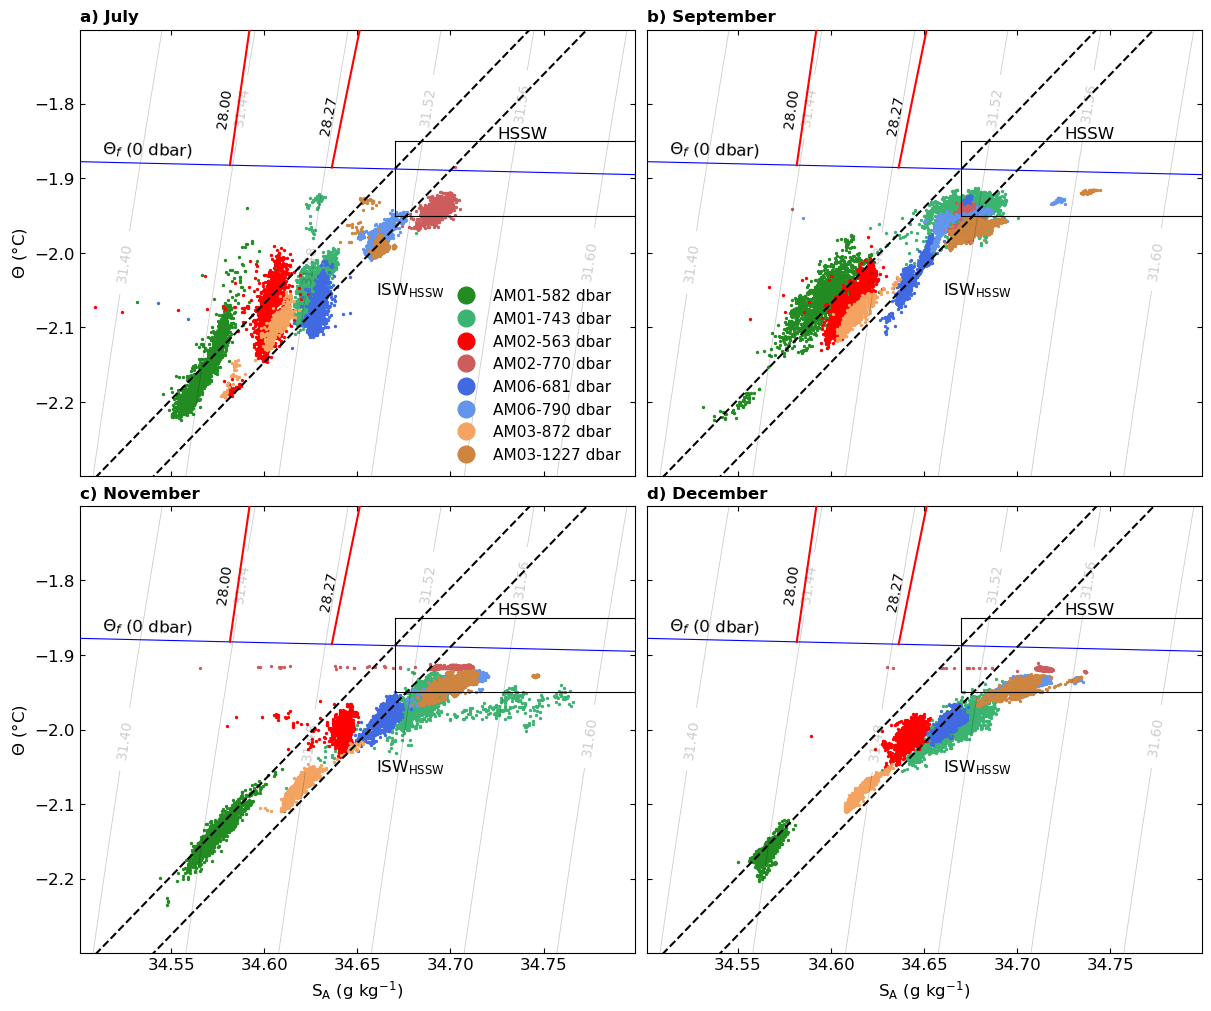

In [53]:
columns = 2
rows = math.ceil(len(months) / columns)

fig, axes = plt.subplots(rows, columns, figsize=(6 * columns, 5 * rows), sharex=True, sharey=True, layout='constrained', squeeze=False)
axes_flat = axes.flatten()

# Define the range of temp and salinity over which to plot overlays
salinity_range = np.linspace(xlim_sal[0], xlim_sal[1], 100)
temp_range = np.linspace(ylim_temp[0], ylim_temp[1], 100)

panel_labels = ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm']

for i, month in enumerate(months):
    # Create a new subplot for this month
    ax = axes_flat[i]
    ax.set_xlim(*xlim_sal)
    ax.set_ylim(*ylim_temp)

    ax.set_title(f"{panel_labels[i]}) " + pd.Timestamp(2001, month, 1).strftime("%B"), loc='left', fontweight="bold")
    
    # -- PLOT OBSERVATIONAL DATA --
    for borehole, cat in cats:
        # Create a mask to filter the dataframe for the specified borehole and cat, in this month
        mask = (df["borehole"] == borehole) & (df["cat"] == cat) & (df["time"].dt.month == month)
        sub = df[mask].copy()

        if years is not None:
            # Raw points for the chosen years only (borehole colour)
            in_years = sub[sub["time"].dt.year.isin(years)]
            ax.scatter(in_years["absolute_salinity"], in_years["conservative_temperature"], c=BOREHOLE_COLOURS[borehole][cat], label="_", zorder=3, **obsv_kw)

            # 95% band around all years of raw data for this MicroCAT in this month (borehole colour, outline only, drawn over the points)
            density_band(ax, sub["absolute_salinity"].values, sub["conservative_temperature"].values, BOREHOLE_COLOURS[borehole][cat])
        else:
            # Extract day of year and year from the time column
            sub["doy"] = sub["time"].dt.dayofyear + sub["time"].dt.hour / 24 + sub["time"].dt.minute / 1440
    
            # Round to nearest half-hour (1/48 of a day) since each MicroCAT records data with a half-hour interval, although due to time drift the equivalent timestamp on different years may not be exactly the same time to the second
            sub["doy_bin"] = (sub["doy"] * 48).round() / 48
            
            agg = "mean" if average == "mean" else "median"
            # Calculate the median/mean temp and salinity values on the equivalent timestamp between different years
            average_sub = sub.groupby("doy_bin")[["conservative_temperature", "absolute_salinity"]].agg(agg).dropna()

            # Plot the T-S datapoints
            ax.scatter(average_sub["absolute_salinity"], average_sub["conservative_temperature"], c=BOREHOLE_COLOURS[borehole][cat], label="_", **obsv_kw)
        
        # Legend proxy for the mooring, on the first panel only (contours don't carry labels)
        if i == 0:
            ax.plot([], [], color=BOREHOLE_COLOURS[borehole][cat], lw=1.2, marker="o", linestyle="none", label=f"{borehole}-{AVG_PRESSURES[cat]:.0f} dbar")

    # -- PLOT OVERLAYS --
    # - Freezing point temperature line at 0 dbar (saturation fraction = 0) -
    CT_freeze_0 = gsw.CT_freezing(salinity_range, 0, 0)
    ax.plot(salinity_range, CT_freeze_0, **freeze_kw)
    label_curve_tangent(ax, salinity_range, CT_freeze_0, 0.125, r"$\Theta_f$ (0 dbar)", "black", FS_SMALL, **curve_label_kwargs)

    # - Isopycnals (potential density anomaly contours) referenced to the average pressure of the plot MicroCATs
    # Reference pressure for the potential density anomaly (dbar)
    pressures = []
    for borehole, cat in cats:
        pressures.append(AVG_PRESSURES[cat])
    reference_pressure = np.mean(pressures)
    print(f"Reference Pressure for Plot: {reference_pressure}")
    
    salinity_grid, temp_grid = np.meshgrid(salinity_range, temp_range)
    sigma = gsw.rho(salinity_grid, temp_grid, reference_pressure) - 1000
    cs = ax.contour(salinity_grid, temp_grid, sigma, **isopycnal_kw)
    ax.clabel(cs, inline=True, fontsize=10, fmt="%.2f")

    # - Neutral density curves from Blanckensee et al. (2024) -
    xc1, yc1 = clip_to_freezing(np.asarray(x_curve1), np.asarray(y_curve1))
    xc2, yc2 = clip_to_freezing(np.asarray(x_curve2), np.asarray(y_curve2))
    ax.plot(xc1, yc1, **neutral_kw)
    ax.plot(xc2, yc2, **neutral_kw)
    label_curve_tangent(ax, xc2, yc2, 0.03, "28.00", "black", 10, **curve_label_kwargs)
    label_curve_tangent(ax, xc1, yc1, 0.03, "28.27", "black", 10, **curve_label_kwargs)

    # - Meltwater mixing line using gsw (equation 16 from McDougall et al. (2014)) -
    # First, assume "the temperature of the glacial ice, -15 C, measured from a thermistor cable at AM01" as per Herraiz-Borreguero et al. (2013) (also used in Silvano et al. (2017))
    t_ice = -15.0

    # REVIEW - WHAT PRESSURE DO WE WANT TO PUT HERE?? (note: slope is not particularly sensitive to this pressure) (2nd note: the slope doesn't seem to change at all regardless of what value we use between 0 and 1000 dbar)
    pressure_source = 550

    # We also need to define conditions of the source water mass - should generally be identified as the warmest/saltiest water mass in the visible datapoints
    # Initialise a list to hold the meltwater mixing line curves
    # gade_curves = []
    for salinity_source in meltwater_mixing_lines:
        # Here, we will define the temp of the source water mass as the surface (0 dbar) freezing point temperature at the given source salinities we have chosen
        temp_source = float(gsw.CT_freezing(salinity_source, 0, 0))
        dSA_dCT = gsw.ice.melting_ice_SA_CT_ratio(salinity_source, temp_source, pressure_source, t_ice)
        slope = 1 / dSA_dCT  # dCT/dSA
        CT_gade = temp_source + slope * (salinity_range - salinity_source)
        ax.plot(salinity_range, CT_gade, **gade_kw)
        # gade_curves.append((salinity_source, temp_source, slope))
    # Now we will fill the space between the two defined meltwater mixing lines, capped above by the 0 dbar freezing point temp
    # if len(gade_curves) == 2:
    #     (S_lo, T_lo, m_lo), (S_hi, T_hi, m_hi) = sorted(gade_curves)
    #     # Where each mixing line leaves the bottom of the axes
    #     y_bot = ylim_temp[0]
    #     x_lo_bot = S_lo + (y_bot - T_lo) / m_lo
    #     x_hi_bot = S_hi + (y_bot - T_hi) / m_hi
    #     # The freezing curve segment spanning the two source salinities forms the upper bound
    #     s_cap = np.linspace(S_lo, S_hi, 50)
    #     t_cap = gsw.CT_freezing(s_cap, 0, 0)
    #     # Walk the boundary: up the low-salinity line, along the freezing cap, back down the high-salinity line
    #     poly_x = np.concatenate([[x_lo_bot], s_cap, [x_hi_bot]])
    #     poly_y = np.concatenate([[y_bot], t_cap, [y_bot]])
    #     ax.fill(poly_x, poly_y, color="k", alpha=0.08, lw=0, zorder=0)

    # - High Salinity Shelf Water - 
    # Define after Herraiz-Borreguero et al. (2015) and Rosevear et al. (2022) - -1.95 <= Theta <= -1.85 and S_A > 34.67 g/kg
    hssw_temp = (-1.95, -1.85)
    hssw_sal_min = 34.67
    ax.plot([hssw_sal_min, xlim_sal[1]], [hssw_temp[0], hssw_temp[0]], color="black", linestyle="-", lw=0.8, label="_", zorder=4)
    ax.plot([hssw_sal_min, xlim_sal[1]], [hssw_temp[1], hssw_temp[1]], color="black", linestyle="-", lw=0.8, label="_", zorder=4)
    ax.plot([hssw_sal_min, hssw_sal_min], [hssw_temp[0], hssw_temp[1]], color="black", linestyle="-", lw=0.8, label="_", zorder=4)
    ax.text(34.725, hssw_temp[1], "HSSW", color="black", va="bottom", ha="left", zorder=2)

    # - ISW_HSSW - 
    ax.text(34.66, -2.05, r"$\mathrm{ISW_{HSSW}}$", color="black", va="center", ha="left", zorder=2)

# Hide any unused subplots
for j in range(len(months), rows * columns):
    axes_flat[j].axis("off")

for ax in axes_flat:
    ax.tick_params(axis="both", direction="in", top=True, right=True)

# Set the y-axis label for the leftmost plots only
for r in range(rows):
    axes[r, 0].set_ylabel(r"$\Theta$ (°C)", **label_kw)

# Set the x-axis label on the lowest panel in each column (taking into account a last row that isn't full)
for c in range(min(columns, len(months))):
    ax = axes_flat[c + columns * ((len(months) - 1 - c) // columns)]
    ax.set_xlabel(r"$\mathrm{S_{A} \ (g \ kg^{-1})}$", **label_kw)
    # sharex hides tick labels on non-bottom rows — turn them back on here
    ax.tick_params(axis="x", labelbottom=True)

# -- DRAW LEGEND --
axes_flat[0].legend(loc='lower right', fontsize=11, **legend_kw)

fig.savefig('/g/data/gv90/ad6790/amery-amisor/notebooks/figures/ObsT-SHSSW.jpg', format='jpg', dpi=600)
plt.show()

## Figure SI: T-S Space HSSW Isothermal Summer Salinity Signal

In [54]:
# Define the borehole, associated MicroCAT at that borehole and then the proxy location in the model within one tuple
# (borehole, MicroCAT, [model proxy locations])
boreholes = [("AM02", "1174"), ("AM06", "7323"), ("AM03", "3883")]

# Define the months to be plotted
months = [10,11,12,1,2]

# Define a single year to plot (if desired)
years = None

# Define if the composite data will determined using mean or median
average = "mean"

# Initialise a list of salinity values corresponding to the source water mass at ~-1.9C
meltwater_mixing_lines = [34.67, 34.7]

# Define the limits of the y-axes for plots of temperature and salinity
ylim_temp = (-2.099, -1.801)
xlim_sal = (34.601, 34.75)

Reference Pressure for Plot: 770.2
Reference Pressure for Plot: 770.2
Reference Pressure for Plot: 770.2
Reference Pressure for Plot: 770.2
Reference Pressure for Plot: 770.2
Reference Pressure for Plot: 790.3
Reference Pressure for Plot: 790.3
Reference Pressure for Plot: 790.3
Reference Pressure for Plot: 790.3
Reference Pressure for Plot: 790.3
Reference Pressure for Plot: 1227.1
Reference Pressure for Plot: 1227.1
Reference Pressure for Plot: 1227.1
Reference Pressure for Plot: 1227.1
Reference Pressure for Plot: 1227.1


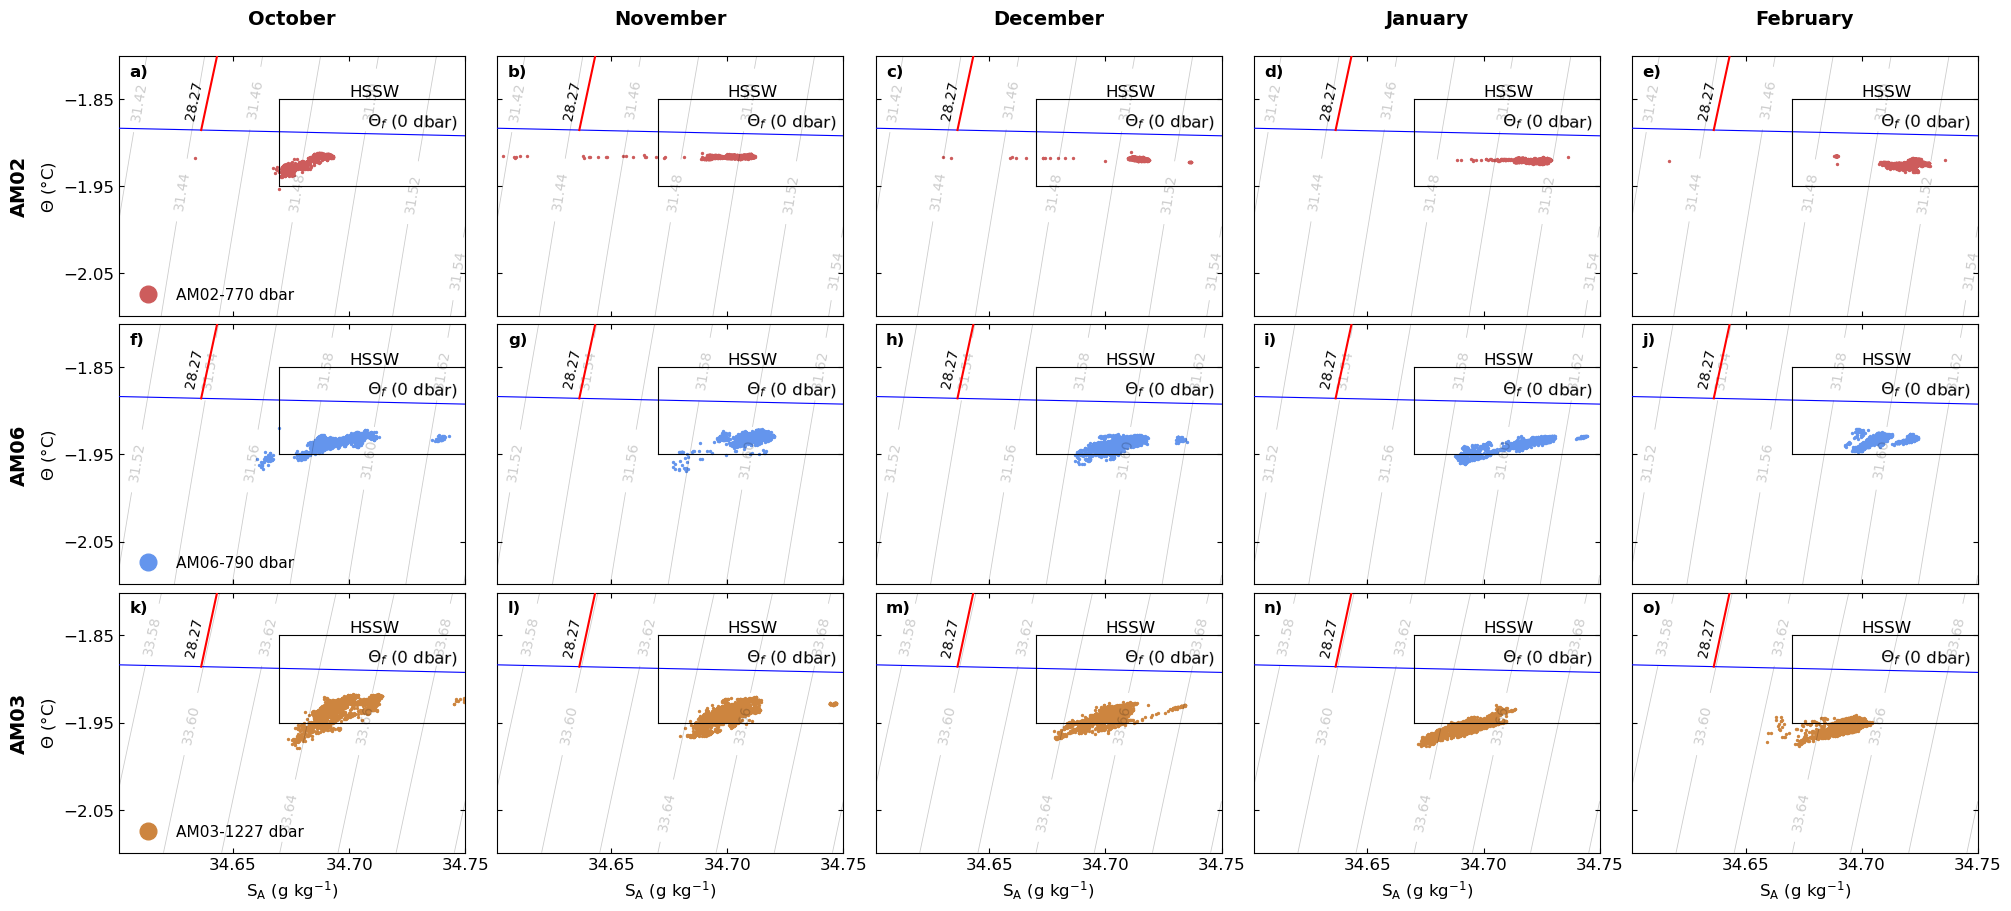

In [55]:
rows = len(boreholes)
columns = len(months)

fig, axes = plt.subplots(rows, columns, figsize=(4 * columns, 3 * rows), sharex=True, sharey=True, layout='constrained', squeeze=False)
axes_flat = axes.flatten()

# Define the range of temp and salinity over which to plot overlays
salinity_range = np.linspace(xlim_sal[0], xlim_sal[1], 100)
temp_range = np.linspace(ylim_temp[0], ylim_temp[1], 100)

for row, (borehole, cat) in enumerate(boreholes):
    for col, month in enumerate(months):
        ax = axes[row, col]
        ax.set_xlim(*xlim_sal)
        ax.set_ylim(*ylim_temp)

        ax.xaxis.set_major_locator(mticker.MultipleLocator(0.05, offset=0.05))    # salinity, g/kg
        ax.yaxis.set_major_locator(mticker.MultipleLocator(0.1, offset=0.05))    # temperature, °C

        ax.text(0.03, 0.97, f"{chr(97 + row * columns + col)})", transform=ax.transAxes, ha="left", va="top", fontweight="bold", zorder=10)

        # -- PLOT OBSERVATIONAL DATA --
        # Create a mask to filter the dataframe for the specified borehole and cat, in this month
        mask = (df["borehole"] == borehole) & (df["cat"] == cat) & (df["time"].dt.month == month)
        sub = df[mask].copy()

        if years is not None:
            # Raw points for the chosen years only (borehole colour)
            in_years = sub[sub["time"].dt.year.isin(years)]
            ax.scatter(in_years["absolute_salinity"], in_years["conservative_temperature"], c=BOREHOLE_COLOURS[borehole][cat], label="_", zorder=3, **obsv_kw)

            # 95% band around all years of raw data for this MicroCAT in this month (borehole colour, outline only, drawn over the points)
            density_band(ax, sub["absolute_salinity"].values, sub["conservative_temperature"].values, BOREHOLE_COLOURS[borehole][cat])
        else:
            # Extract day of year and year from the time column
            sub["doy"] = sub["time"].dt.dayofyear + sub["time"].dt.hour / 24 + sub["time"].dt.minute / 1440

            # Round to nearest half-hour (1/48 of a day) since each MicroCAT records data with a half-hour interval, although due to time drift the equivalent timestamp on different years may not be exactly the same time to the second
            sub["doy_bin"] = (sub["doy"] * 48).round() / 48

            agg = "mean" if average == "mean" else "median"
            # Calculate the median/mean temp and salinity values on the equivalent timestamp between different years
            average_sub = sub.groupby("doy_bin")[["conservative_temperature", "absolute_salinity"]].agg(agg).dropna()

            # Plot the T-S datapoints
            ax.scatter(average_sub["absolute_salinity"], average_sub["conservative_temperature"], c=BOREHOLE_COLOURS[borehole][cat], label="_", **obsv_kw)

            # Legend proxy for the mooring, on the first panel only (contours don't carry labels)
            if col == 0:
                ax.plot([], [], color=BOREHOLE_COLOURS[borehole][cat], lw=1.2, marker="o", linestyle="none", label=f"{borehole}-{AVG_PRESSURES[cat]:.0f} dbar")

        # -- PLOT OVERLAYS --
        # - Freezing point temperature line at 0 dbar (saturation fraction = 0) -
        CT_freeze_0 = gsw.CT_freezing(salinity_range, 0, 0)
        ax.plot(salinity_range, CT_freeze_0, **freeze_kw)
        label_curve_tangent(ax, salinity_range, CT_freeze_0, 0.85, r"$\Theta_f$ (0 dbar)", "black", FS_SMALL, **curve_label_kwargs)

        # - Isopycnals, using the reference pressure worked out above -
        reference_pressure = np.mean(AVG_PRESSURES[cat])
        print(f"Reference Pressure for Plot: {reference_pressure}")

        salinity_grid, temp_grid = np.meshgrid(salinity_range, temp_range)
        sigma = gsw.rho(salinity_grid, temp_grid, reference_pressure) - 1000
        cs = ax.contour(salinity_grid, temp_grid, sigma, **isopycnal_kw)
        ax.clabel(cs, inline=True, fontsize=10, fmt="%.2f")

        # - Neutral density curves from Blanckensee et al. (2024) -
        xc1, yc1 = clip_to_freezing(np.asarray(x_curve1), np.asarray(y_curve1))
        xc2, yc2 = clip_to_freezing(np.asarray(x_curve2), np.asarray(y_curve2))
        ax.plot(xc1, yc1, **neutral_kw)
        ax.plot(xc2, yc2, **neutral_kw)
        label_curve_tangent(ax, xc2, yc2, 0.03, "28.00", "black", 10, **curve_label_kwargs)
        label_curve_tangent(ax, xc1, yc1, 0.02, "28.27", "black", 10, **curve_label_kwargs)

        # - Meltwater mixing line using gsw (equation 16 from McDougall et al. (2014)) -
        # First, assume "the temperature of the glacial ice, -15 C, measured from a thermistor cable at AM01" as per Herraiz-Borreguero et al. (2013) (also used in Silvano et al. (2017))
        t_ice = -15.0

        # REVIEW - WHAT PRESSURE DO WE WANT TO PUT HERE?? (note: slope is not particularly sensitive to this pressure) (2nd note: the slope doesn't seem to change at all regardless of what value we use between 0 and 1000 dbar)
        pressure_source = 550

        # We also need to define conditions of the source water mass - should generally be identified as the warmest/saltiest water mass in the visible datapoints
        # Initialise a list to hold the meltwater mixing line curves
        # for salinity_source in meltwater_mixing_lines:
        #     # Here, we will define the temp of the source water mass as the surface (0 dbar) freezing point temperature at the given source salinities we have chosen
        #     temp_source = float(gsw.CT_freezing(salinity_source, 0, 0))
        #     dSA_dCT = gsw.ice.melting_ice_SA_CT_ratio(salinity_source, temp_source, pressure_source, t_ice)
        #     slope = 1 / dSA_dCT  # dCT/dSA
        #     CT_gade = temp_source + slope * (salinity_range - salinity_source)
        #     ax.plot(salinity_range, CT_gade, **gade_kw)

        # - High Salinity Shelf Water -
        # Define after Herraiz-Borreguero et al. (2015) and Rosevear et al. (2022) - -1.95 <= Theta <= -1.85 and S_A > 34.67 g/kg
        hssw_temp = (-1.95, -1.85)
        hssw_sal_min = 34.67
        ax.plot([hssw_sal_min, xlim_sal[1]], [hssw_temp[0], hssw_temp[0]], color="black", linestyle="-", lw=0.8, label="_", zorder=4)
        ax.plot([hssw_sal_min, xlim_sal[1]], [hssw_temp[1], hssw_temp[1]], color="black", linestyle="-", lw=0.8, label="_", zorder=4)
        ax.plot([hssw_sal_min, hssw_sal_min], [hssw_temp[0], hssw_temp[1]], color="black", linestyle="-", lw=0.8, label="_", zorder=4)
        ax.text(34.7, hssw_temp[1], "HSSW", color="black", va="bottom", ha="left", zorder=2)

        # - ISW_HSSW -
        # ax.text(34.66, -2.05, r"$\mathrm{ISW_{HSSW}}$", color="black", va="center", ha="left", zorder=2)

    # -- DRAW LEGEND --
    axes[row, 0].legend(loc='lower left', fontsize=11, **legend_kw)

for ax in axes_flat:
    ax.tick_params(axis="both", direction="in", top=True, right=True)

# Set the y-axis label for the leftmost plots only
for r in range(rows):
    axes[r, 0].set_ylabel(r"$\Theta$ (°C)", **label_kw)

for c in range(columns):
    axes[-1, c].set_xlabel(r"$\mathrm{S_{A} \ (g \ kg^{-1})}$", **label_kw)

# Month names across the top of each column
for c, month in enumerate(months):
    axes[0, c].annotate(pd.Timestamp(2001, month, 1).strftime("%B"), xy=(0.5, 1), xycoords="axes fraction", xytext=(0, 20), textcoords="offset points", ha="center", va="bottom", fontweight="bold", fontsize=14)

# Borehole names down the left of each row
for r, (borehole, cat) in enumerate(boreholes):
    axes[r, 0].annotate(borehole, xy=(0, 0.5), xycoords="axes fraction", xytext=(-65, 0), textcoords="offset points", ha="right", va="center", rotation=90, fontweight="bold", fontsize=14)

fig.savefig('/g/data/gv90/ad6790/amery-amisor/notebooks/figures/ObsT-SHSSW_Isothermal.jpg', format='jpg', dpi=600)
plt.show()